# PCA and SVD: projection, compression, geometry, and conditioning

## 1. Introduction and learning objectives

Principal component analysis (PCA) chooses an affine subspace that preserves squared variation in a declared geometry. Singular value decomposition (SVD) supplies the numerical factorization. These tools explain compression, redundancy and weak directions; they do not automatically find semantic features or the directions useful for a future prediction task. Understanding that distinction is part of evaluating modern learned representations and low-rank methods.

Derive the projection/variance/reconstruction equivalence; implement a training-fitted PCA interface using a thin SVD; validate derivatives and identities independently; and investigate scale, whitening, rank and numerical conditioning. NumPy's SVD/eigensolvers are numerical primitives. You implement the surrounding statistics, objectives, transforms and evaluations manually. No new dependency or GPU is needed.

**Prerequisites:** Stage 00 matrix calculus, covariance and precision; Stage 01 training/validation boundaries. The earlier clustering/mixture chapters provide context but no live functions are required. Observations are rows of $X\in\mathbb R^{n\times d}$. The covariance convention throughout is $1/n$, not $1/(n-1)$.

## 2. Prerequisites and mathematical foundations

Fit the training mean $\mu\in\mathbb R^d$ and optional feature scales $s\in\mathbb R_{>0}^d$. Write $A=(X-\mu)/s$, using coordinate-wise division. With no standardization, $s_j=1$. With standardization, $s_j$ is the training population standard deviation; a constant training feature gets scale one and is recorded. Reuse both arrays for new observations. Recomputing their means or scales on validation data changes the representation and leaks information into the fitted preprocessing.

Let $V\in\mathbb R^{d\times k}$ have orthonormal columns, $V^TV=I_k$. Scores are $Z=AV$ with shape $(n,k)$, projection is $\hat A=ZV^T=AP$, and $P=VV^T$ is symmetric and idempotent. Reconstruction in original units is $\hat X=\hat A\odot s+\mu$. A zero-component representation reconstructs every observation as the training mean. A partial projection is not an invertible map on the full feature space.

Our reconstruction distortion is $D=\|A-AP\|_F^2/n$, summing squared feature errors per observation. It is not half-MSE, and it does not additionally divide by $d$. When scales differ, it is a weighted squared error in original units, $n^{-1}\sum_{ij}(x_{ij}-\hat x_{ij})^2/s_j^2$. Minimizing it need not minimize an unweighted raw-unit error.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 03.03.01 — Specify what a representation is meant to preserve

**Type:** Conceptual · **Answer:** Markdown

Explain the shapes and roles of mean, scales, components, scores and reconstruction. Give a concrete example in which raw-unit compression, standardized compression and predictive usefulness are different goals. Which statistics may be fitted using validation rows?

**Expected outcome:** a declared geometry/objective and an explicit distinction between compression, prediction and preprocessing information.

**Your response to Exercise 03.03.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.01**

An unsupervised transform still learns from observations. Unit conversions can change an unstandardized squared-error objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.01**

The mean/scales have shape $(d,)$, components $(d,k)$, scores $(n,k)$ and reconstruction $(n,d)$. Compressing a physical measurement and a financial amount in their raw units gives weights that change with the units; standardization defines another metric. Neither metric necessarily preserves the low-variance signal that predicts a target. Fit means, scales and components on training rows only. Validation may support a predeclared selection decision, but its observations must not be used to refit the preprocessing for that comparison. State the objective, selected dimension and information boundary before interpreting a useful-looking scatterplot.

</details>

## 3. Theoretical development and worked examples

### Variance and orthogonal reconstruction

Since training $A$ is centered, define $C=A^TA/n$. For a unit direction $v$, projected population variance is $v^TCv$. A Lagrange multiplier for $v^Tv=1$ gives $Cv=\lambda v$; the leading eigenvector maximizes the Rayleigh quotient. For $k$ orthonormal directions,
$$\frac1n\|A-AVV^T\|_F^2=\operatorname{tr}(C)-\operatorname{tr}(V^TCV).$$
Expand the squared norm and use $P^T=P$, $P^2=P$. Therefore maximizing retained variance minimizes this reconstruction error. If $C=Q\operatorname{diag}(\lambda)Q^T$ with descending eigenvalues, write $B=Q^TV$. Each row squared norm $b_j$ lies in $[0,1]$ and $\sum_jb_j=k$. Hence $\sum_j\lambda_jb_j\le\sum_{j=1}^k\lambda_j$, achieved by the leading eigenvectors. Minimum distortion is the sum of discarded eigenvalues.

The axes can change sign without changing the subspace. Within a repeated-eigenvalue block, rotations are also valid. The top-$k$ projector is unique when a positive gap separates retained and discarded eigenvalues; at a boundary tie, several different projectors can be optimal. Compare projectors or reconstruction objectives where appropriate, not elementwise eigenvectors with arbitrary signs. This notebook fixes the largest-magnitude loading of each reported axis to be nonnegative, but that convention does not resolve tied eigenspaces.

### Thin SVD and spectrum conventions

For $r=\min(n,d)$, a thin SVD is $A=U\operatorname{diag}(\sigma)V_r^T$, where $U$ has shape $(n,r)$, $V_r$ shape $(d,r)$ and descending $\sigma_j\ge0$. Thus the covariance eigenvalues are $\lambda_j=\sigma_j^2/n$, with additional zero values when $d>r$. Centering limits exact rank to at most $\min(n-1,d)$. A finite numerical rank also needs a declared tolerance; here it is $\max(n,d)\epsilon_{64}\sigma_1$.

PCA uses leading right singular vectors. It agrees with truncated-SVD matrix reconstruction on the centered/preprocessed matrix. SVD of the raw matrix instead compresses through the origin and can spend its capacity representing a large mean. Changing the covariance divisor to $n-1$ multiplies eigenvalues by $n/(n-1)$ without changing axes or variance ratios. It does change the normalization needed for whitening.

The explained-variance ratio is $\lambda_j/\operatorname{tr}(C)$ when total variance is positive. For a constant data matrix, we report zero ratios and zero numerical rank, rather than inventing a meaningful variance fraction. Choosing a dimension that retains null directions adds nonidentified axes; it does not add observed training information.

### Whitening and conditioning

For retained positive eigenvalues, whitening uses $Z_w=AV\operatorname{diag}(\lambda^{-1/2})$, giving training covariance $Z_w^TZ_w/n=I_k$. Undo those score scales before reconstructing: $\hat A=Z_w\operatorname{diag}(\lambda^{1/2})V^T$. Whitening changes score-space distances and amplifies weak directions. It does not improve the PCA reconstruction when the same axes and inverse scaling are used. Null or numerically null directions cannot be whitened under this contract.

On a full-column-rank matrix, the 2-norm condition number of $A^TA$ is the square of that of $A$. Forming a covariance matrix can lose weak directions through rounding. A direct SVD avoids explicitly squaring the spectrum, but cannot recover information already lost when the input was rounded. A negative tiny computed covariance eigenvalue can be a numerical artifact even though the exact covariance is positive semidefinite; record it when auditing a method instead of disguising it as exact mathematics.

### Hand example and derivative contract

For four rows $(-2,-1),(-2,1),(2,-1),(2,1)$, the mean is zero, $C=\operatorname{diag}(4,1)$, singular values are $(4,2)$ and variance ratios $(.8,.2)$. One-component PCA retains the horizontal axis. Its total squared residual is four and mean per-observation distortion one. Whitening divides horizontal scores by two, giving population variance one; undoing that factor gives the same reconstruction.

For an arbitrary trial matrix $W\in\mathbb R^{d\times k}$, define the **half** distortion $L(W)=\|A-AWW^T\|_F^2/(2n)$. With $E=A-AWW^T$,
$$\nabla_WL=-\frac1n(A^TE+E^TA)W.$$
Derive this by differentiating both appearances of $W$. This function is defined even when $W$ is not orthonormal, but its reconstruction is then not necessarily an orthogonal projection. A derivative check is not permission to drop PCA's orthonormal constraint when claiming an optimum. Zero $W$ is stationary for this unconstrained expression and is usually a poor compression.

### Exercise 03.03.02 — Derive the variance and reconstruction equivalence

**Type:** Mathematical · **Answer:** Markdown

Derive the Rayleigh equation, trace identity, eigenvalue bound and minimum discarded-variance distortion. Track the $1/n$ convention and all shapes. Explain what changes under a $1/(n-1)$ covariance convention and under feature standardization.

**Expected outcome:** a constrained optimization derivation, correct normalization and a stated metric for the reconstruction error.

**Your response to Exercise 03.03.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.02**

Use a symmetric idempotent projector and cyclic traces. In an eigenbasis, retained row weights sum to $k$ and cannot exceed one individually.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.02**

The unit-vector Lagrangian gives $2Cv-2\lambda v=0$. Expanding $\|A-AP\|_F^2$ produces $\operatorname{tr}(A^TA)-2\operatorname{tr}(PA^TA)+\operatorname{tr}(PA^TAP)$; idempotence reduces the last term to one retained trace. Dividing by $n$ yields total minus retained covariance variance. The eigenbasis weight bound makes the leading $k$ eigenvalues maximal, leaving their tail sum as minimum distortion. The sample-divisor covariance rescales every eigenvalue by $n/(n-1)$ while the actual declared distortion still uses $1/n$. Standardization changes $A$ and therefore the metric; tail variance then measures standardized error, not unweighted raw-feature error.

</details>

### Exercise 03.03.03 — Reconstruct and whiten the hand rectangle

**Type:** Numerical · **Answer:** Markdown

Calculate its mean, covariance, singular values, one-component scores, reconstruction, residual SSE and distortion. Whiten those scores and calculate covariance with both $1/n$ and $1/(n-1)$ divisors. Explain why a nonzero discarded eigenvalue prevents exact reconstruction.

**Expected outcome:** spectrum $(4,1)$, ratio $.8$, residual SSE four, distortion one, and whitened covariance one or $4/3$ depending on the divisor.

**Your response to Exercise 03.03.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.03**

The retained scores are $(-2,-2,2,2)$. Removing the vertical coordinate loses four residual values with square one.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.03**

The zero mean and symmetric signs remove cross covariance. Coordinate variances are four and one, hence singular values $\sqrt{4\cdot4}=4$ and $\sqrt{4\cdot1}=2$. Projection gives rows $(\mp2,0)$ in the original order, with total residual four. Whitened scores are $(-1,-1,1,1)$, whose sum of squares is four: division by four yields one, while division by three yields $4/3$. The missing vertical variation has positive variance, so one horizontal coordinate cannot reconstruct it for this sample.

</details>

### Exercise 03.03.04 — Handle tied axes and numerically null whitening

**Type:** Mathematical · **Answer:** Markdown

For $C=I_2$, compare a horizontal one-dimensional projector with a 45-degree one. Do they have the same distortion? Are the projectors equal? Then consider $C=\operatorname{diag}(4,0)$ and explain why keeping two unwhitened axes differs from attempting to whiten both. State a valid comparison when two numerical solvers return different signs or tied bases.

**Expected outcome:** correct nonuniqueness at a boundary tie, equal optimal objective without identical projectors, and an explicit zero-variance limitation.

**Your response to Exercise 03.03.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.04**

A projector is unique only for a separated retained subspace. A sign flip changes a basis but not its projector.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.04**

For $I_2$, every unit direction retains variance one and discards one. The horizontal projector and the projector onto $(1,1)/\sqrt2$ are different matrices with the same optimal distortion. A full two-dimensional projector is identity and is unique even though its basis is not. For $\operatorname{diag}(4,0)$, a second unwhitened axis adds no observed training variation; dividing its score by zero is undefined. A numerical tolerance treats sufficiently weak directions similarly. Compare projectors for a uniquely separated subspace, or objective/reconstruction and full tied-block spans when a boundary tie permits multiple optima. Do not force arbitrary vector signs or individual tied axes to match.

</details>

## 4. Guided exercises

### Exercise 03.03.05 — Fit training statistics and a thin-SVD PCA model

**Type:** Programming · **Answer:** Code

Implement `fit_pca(X, k, standardize=False, whiten=False)`. Bound fits to 2–2,000 rows and 1–64 features, permit $k=0$ through $\min(n,d)$, and retain training mean/scales, constant-feature mask, components, full covariance spectrum, ratios, numerical rank/tolerance and score scales. Use a thin SVD and the stated sign convention. Reject whitening of numerically null axes and explicit variance range failures. Preserve input arrays.

**Expected outcome:** tall/wide/constant/rank-deficient models with explicit conventions and no validation-fitted preprocessing.

In [ ]:
# Your code for Exercise 03.03.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.05**

Compute column standard deviations using a scaled norm to avoid squaring tiny/huge centered values before normalization. Thin SVD controls factor dimensions, not a change to PCA's objective.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.05**

These helpers are local to this chapter. Standardization uses training population standard deviations and scale one for constant columns. A direct SVD supplies axes; all model statistics and conventions remain visible. Variance underflow is diagnosed rather than turning a representable nonzero singular value into an asserted constant-variance direction. The numerical-rank threshold is a diagnostic choice, not a universal dimension selector.

~~~python
def pca_features(X, allow_empty=False):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or not 1 <= X.shape[1] <= 64 or (not allow_empty and len(X) == 0) or not np.isfinite(X).all():
        raise ValueError('finite (n, d) rows with 1..64 features required')
    return X

def fit_pca(X, k, standardize=False, whiten=False):
    X = pca_features(X); n,d = X.shape
    if not 2 <= n <= 2000 or isinstance(k,(bool,np.bool_)) or not isinstance(k,(int,np.integer)) or not 0 <= k <= min(n,d):
        raise ValueError('2..2000 fit rows and integer k in 0..min(n,d) required')
    if not isinstance(standardize,(bool,np.bool_)) or not isinstance(whiten,(bool,np.bool_)):
        raise ValueError('standardize/whiten must be booleans')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        mean = X.mean(axis=0); centered = X-mean
        spread = np.max(np.abs(centered),axis=0); active = spread > 0
        scales = np.ones(d)
        if standardize:
            scales[active] = spread[active]*np.sqrt(np.mean((centered[:,active]/spread[active])**2,axis=0))
            if np.any(scales <= 0) or not np.isfinite(scales).all():
                raise FloatingPointError('unrepresentable feature scale')
        A = centered/scales
        _,singular,vt = np.linalg.svd(A,full_matrices=False)
        variances = (singular/np.sqrt(n))**2
        if np.any((singular > 0)&(variances == 0)):
            raise FloatingPointError('nonzero singular-value variance underflow')
        spectrum = np.r_[variances,np.zeros(d-len(variances))]
        total = float(spectrum.sum())
        ratios = spectrum/total if total > 0 else np.zeros(d)
        threshold = max(n,d)*np.finfo(float).eps*singular[0]
        if whiten and np.any(singular[:k] <= threshold):
            raise ValueError('cannot whiten a numerically null component')
        for j in range(len(vt)):
            if vt[j,np.argmax(np.abs(vt[j]))] < 0:
                vt[j] *= -1
        score_scales = np.sqrt(spectrum[:k]) if whiten else np.ones(k)
    return dict(mean=mean,scales=scales,constant_features=~active,components=vt[:k].T.copy(),
        singular_values=singular,explained_variance=spectrum,explained_variance_ratio=ratios,
        numerical_rank=int(np.sum(singular > threshold)),rank_tolerance=float(threshold),
        score_scales=score_scales,n_samples=n,standardize=bool(standardize),whiten=bool(whiten))
~~~

</details>

### Exercise 03.03.06 — Transform and reconstruct with the frozen training model

**Type:** Programming · **Answer:** Code

Implement `pca_transform` and `pca_reconstruct` using only stored training statistics. Support zero components and empty query/score arrays of the correct width. Undo whitening before projection back to original units. Check tall/wide round trips, dimension errors, constant features and a shifted probe that must not recenter itself.

**Expected outcome:** correct $(n,k)$ and $(n,d)$ outputs, a mean-only baseline at $k=0$, consistent whitening and no mutation/refitting.

In [ ]:
# Your code for Exercise 03.03.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.06**

The component matrix has columns as axes. Multiply whitened scores by their stored scale before the matrix product with its transpose.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.06**

This depends on `fit_pca` and the feature validator. The model format is the one returned here, not an arbitrary serialized object schema. A partial inverse is a reconstruction map, not recovery of discarded coordinates. Training-constant columns retain scale one; new variation in those columns is not learned from an unseen sample.

~~~python
def pca_transform(X, model):
    X = pca_features(X,allow_empty=True)
    if X.shape[1] != len(model['mean']):
        raise ValueError('query feature width must match the fitted model')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        return (((X-model['mean'])/model['scales'])@model['components'])/model['score_scales']

def pca_reconstruct(scores, model):
    scores = np.asarray(scores,dtype=float); k = model['components'].shape[1]
    if scores.ndim != 2 or scores.shape[1] != k or not np.isfinite(scores).all():
        raise ValueError('finite (n, k) scores matching the model required')
    with np.errstate(over='raise',invalid='raise'):
        return ((scores*model['score_scales'])@model['components'].T)*model['scales']+model['mean']
~~~

</details>

## 5. Implementation challenges

### Exercise 03.03.07 — Differentiate both appearances of a trial basis

**Type:** Programming · **Answer:** Code

Implement `projection_loss_gradient(A, W)` for the half distortion in the theory section. Check the analytic gradient against central differences of an independent scalar expression for a nonorthonormal trial $W$. Verify dimensions and a zero-column case. Explain why a correct derivative does not make unconstrained optimization of this expression identical to PCA.

**Expected outcome:** a correctly normalized gradient that includes both occurrences of $W$, without silently assuming $W^TW=I$ during differentiation.

In [ ]:
# Your code for Exercise 03.03.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.07**

Differentiate $AWW^T$ in two product-rule terms. Simplifications valid only on orthonormal matrices must not be used for arbitrary finite-difference probes.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.07**

This uses the feature validator. The general residual objective is defined for every finite trial matrix of the right shape. It has extra stationary points, including zero. The PCA optimum proof applies to orthonormal axes and a projector; a derivative check validates the written objective's implementation, not a different optimization problem.

~~~python
def projection_loss_gradient(A, W):
    A = pca_features(A); W = np.asarray(W,dtype=float)
    if W.ndim != 2 or W.shape[0] != A.shape[1] or not np.isfinite(W).all():
        raise ValueError('finite trial basis with shape (d, k) required')
    with np.errstate(over='raise',invalid='raise'):
        residual = A-(A@W)@W.T
        loss = float(np.sum(residual*residual)/(2*len(A)))
        gradient = -(A.T@residual+residual.T@A)@W/len(A)
    return loss,gradient
~~~

</details>

### Exercise 03.03.08 — Audit a fitted projector using independent identities

**Type:** Programming · **Answer:** Code

Implement `pca_training_audit` on the actual training observations. Compare the stored SVD spectrum with a separately formed covariance eigenspectrum; report orthogonality/idempotence errors, reconstruction distortion, discarded-eigenvalue prediction and score covariance. Include both standardized and raw-unit reconstruction errors. Do not hide small negative computed Gram eigenvalues or assume differently signed axes must match.

**Expected outcome:** trace/tail/shape/geometry checks and explicit reporting of numerical residuals, without grading learner answers or claiming covariance formation is always the best solver.

In [ ]:
# Your code for Exercise 03.03.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.08**

The discarded-eigenvalue identity is a training identity in the fitted geometry. It is not a predicted validation error formula.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.08**

This depends on the preceding transform/reconstruction functions. The caller must supply the actual training rows; a same-length different matrix is not the same training sample. The function reports comparisons so mismatched input or numerical limitations can be inspected. It never refits preprocessing. Zero-component matrices have valid empty score covariance and a zero projector.

~~~python
def pca_training_audit(X, model):
    X = pca_features(X)
    if len(X) != model['n_samples'] or X.shape[1] != len(model['mean']):
        raise ValueError('actual training shape required')
    scores = pca_transform(X,model); reconstructed = pca_reconstruct(scores,model)
    V = model['components']; P = V@V.T; k = V.shape[1]
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        A = (X-model['mean'])/model['scales']
        spectrum = np.linalg.eigvalsh(A.T@A/len(X))[::-1]
        standardized_error = float(np.sum(((X-reconstructed)/model['scales'])**2)/len(X))
        raw_error = float(np.sum((X-reconstructed)**2)/len(X))
        score_covariance = scores.T@scores/len(X)
    return dict(covariance_spectrum=spectrum,
        spectrum_max_error=float(np.max(np.abs(spectrum-model['explained_variance']))),
        orthogonality_error=float(np.linalg.norm(V.T@V-np.eye(k))),
        idempotence_error=float(np.linalg.norm(P@P-P)),
        standardized_distortion=standardized_error,raw_distortion=raw_error,
        predicted_training_distortion=float(model['explained_variance'][k:].sum()),
        score_covariance=score_covariance)
~~~

</details>

Squared residuals can give one extreme observation substantial leverage over both the mean and the principal axes. Treat that sensitivity as part of the representation choice before calling a dominant direction a stable scientific structure.

### Exercise 03.03.09 — Quantify an outlier's effect on the mean and principal axis

**Type:** Numerical · **Answer:** Markdown

Start with rows $(-2,0),(-1,0),(1,0),(2,0)$, then append $(0,10)$. Compute each sample's mean, population covariance and leading PCA direction. Evaluate the new affine rank-one projector on the four clean rows. Does its dominant training variance demonstrate a useful representation of the clean horizontal variation?

**Expected outcome:** clean covariance $\operatorname{diag}(2.5,0)$; augmented mean $(0,2)$ and covariance $\operatorname{diag}(2,16)$; a vertical leading axis and clean-probe distortion $2.5$.

**Your response to Exercise 03.03.09**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.09**

The four clean vertical residuals become minus two; the appended residual is eight. Cross terms cancel by horizontal symmetry.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.09**

The clean sample has zero mean, horizontal squared sum ten and covariance $\operatorname{diag}(10/4,0)$. After appending the point, horizontal variance is $10/5=2$ and vertical variance $(4\cdot4+64)/5=16$, with mean $(0,2)$ and zero cross covariance. The leading axis changes from horizontal to vertical. Its affine projection maps each clean point to $(0,0)$, losing horizontal squared sum ten and giving probe distortion $10/4=2.5$. The dominant augmented variance is a correct property of that contaminated sample, not evidence that it preserves the intended clean signal. A robustness claim needs a declared contamination model and separate evaluation.

</details>

## 6. Experiments and visualizations

The default demonstration plots the **given hand rectangle**, its horizontal projection and the analytically known spectrum/tail errors. It does not execute a general fitting answer or define its reference functions. Experimental references below separately fit models and report actual observations.

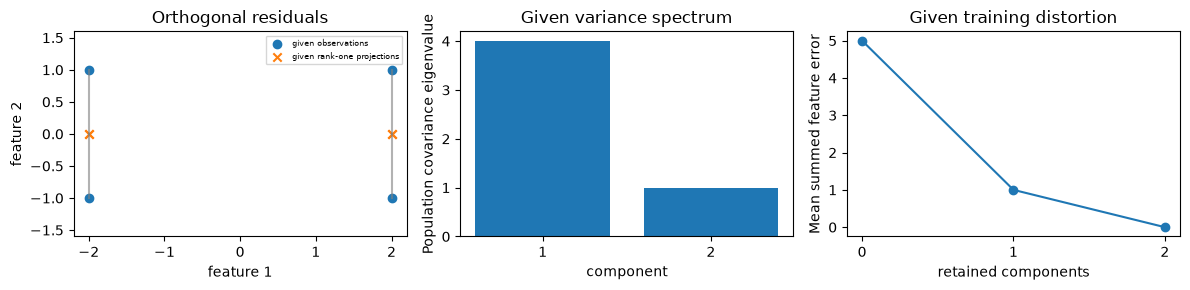

In [2]:
fig,axes = plt.subplots(1,3,figsize=(12,3))
given_rectangle = np.array([[-2.,-1.],[-2.,1.],[2.,-1.],[2.,1.]])
axes[0].scatter(*given_rectangle.T,label='given observations')
axes[0].scatter(given_rectangle[:,0],np.zeros(4),marker='x',label='given rank-one projections')
for x,y in given_rectangle:
    axes[0].plot([x,x],[y,0],color='gray',alpha=.6)
axes[0].set(xlabel='feature 1',ylabel='feature 2',title='Orthogonal residuals',ylim=(-1.6,1.6)); axes[0].legend(fontsize=6)
axes[1].bar([1,2],[4,1]); axes[1].set(xticks=[1,2],xlabel='component',ylabel='Population covariance eigenvalue',title='Given variance spectrum')
axes[2].plot([0,1,2],[5,1,0],marker='o')
axes[2].set(xticks=[0,1,2],xlabel='retained components',ylabel='Mean summed feature error',title='Given training distortion')
fig.tight_layout(); plt.show()

### Exercise 03.03.10 — Measure dimension and reconstruction on separate samples

**Type:** Experimental · **Answer:** Code

Generate 120 training and 160 independent validation rows with seed 280 using the fixed rank-two signal plus six-coordinate Gaussian noise below. Fit unstandardized PCA for $k=0,\ldots,6$ on training rows only. Report training distortion, predicted training eigenvalue tail, validation distortion, retained variance and numerical rank; measure actual elapsed time. Plot the spectrum and both reconstruction curves. Explain why a full six-dimensional basis can reconstruct validation rows exactly without identifying a meaningful latent dimension.

**Expected outcome:** actual dimension curves, a verified training identity, and an evaluation that does not mistake reconstruction alone for a noise/complexity tradeoff.

In [ ]:
# Your code for Exercise 03.03.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.10**

For a fixed nested orthonormal basis, adding directions cannot increase projection error on any sample. A penalty, noise model or declared downstream task is needed for a nontrivial dimension choice.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.10**

This uses the preceding PCA fit, transform/reconstruction and audit functions. Every training statistic is frozen before validation transformation. The known two-dimensional generating signal has added full-dimensional noise, so exact/numerical data rank is not automatically the signal dimension. Validation reconstruction can also keep improving through all six directions. The experiment reports those actual curves rather than inventing an overfitting U-curve or selecting a dimension on an unannounced target metric.

~~~python
from time import perf_counter

def pca_experiment_data(seed=280):
    rng = np.random.default_rng(seed)
    loadings = np.array([[2.,1.,0.,-.5,1.,.2],[0.,.4,1.5,1.,-.3,.7]])
    offset = np.array([3.,-2.,1.,0.,4.,-1.])
    def draw(n):
        return rng.normal(size=(n,2))@loadings+.15*rng.normal(size=(n,6))+offset
    return draw(120),draw(160)

rank_train,rank_validation = pca_experiment_data()
rank_results = []; rank_started = perf_counter()
for k in range(7):
    model = fit_pca(rank_train,k); audit = pca_training_audit(rank_train,model)
    reconstructed = pca_reconstruct(pca_transform(rank_validation,model),model)
    record = dict(k=k,training=audit['standardized_distortion'],
        predicted=audit['predicted_training_distortion'],
        validation=float(np.sum((rank_validation-reconstructed)**2)/len(rank_validation)),
        retained=float(model['explained_variance_ratio'][:k].sum()),numerical_rank=model['numerical_rank'])
    rank_results.append(record); print('dimension',record)
print('dimension study seconds',perf_counter()-rank_started)
fig,axes = plt.subplots(1,2,figsize=(9,3))
axes[0].semilogy(range(1,7),model['explained_variance'],marker='o')
axes[0].set(xlabel='component',ylabel='Training covariance eigenvalue',title='Signal plus full-dimensional noise')
for key in ('training','validation'):
    axes[1].plot(range(7),[record[key] for record in rank_results],marker='.',label=key)
axes[1].set(xlabel='retained components',ylabel='Mean summed feature error',title='Reconstruction alone favors capacity')
axes[1].legend(); fig.tight_layout(); plt.show()
~~~

</details>

### Exercise 03.03.11 — Separate feature scaling from score whitening

**Type:** Experimental · **Answer:** Code

Use the preceding training/validation samples and multiply their coordinates by $(1,1,20,.1,1,1)$. Fit three two-component procedures: raw PCA, standardized PCA, and standardized PCA with whitening. Fit all statistics on the same training rows. Report training score covariance, fitted-geometry training error, validation reconstruction error after undoing the known unit conversion, and mean distance of 80 predeclared validation score pairs. Plot training/validation scores and identify which quantities have comparable units across procedures.

**Expected outcome:** measured effects of changing the fitting metric versus rescaling retained scores; whitening and its inverse preserve a fixed PCA reconstruction.

In [ ]:
# Your code for Exercise 03.03.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.11**

Raw and standardized PCA optimize different feature-weighted distortions. Whitening happens after selecting standardized axes and changes distances in score space.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.11**

This depends on the preceding sample-generation experiment and PCA helpers. The known coordinate multipliers are a controlled unit conversion; undoing them permits reconstruction comparisons in one common original feature metric. Score distances still have different scales, so their numerical sizes are not a universal quality ranking. Standardized whitening should leave the standardized PCA reconstruction unchanged within numerical tolerance when correctly inverted. It does not make the representation independent, noise-free or optimal for an unspecified target.

~~~python
coordinate_units = np.array([1.,1.,20.,.1,1.,1.])
geometry_train,geometry_validation = rank_train*coordinate_units,rank_validation*coordinate_units
geometry_results = []; geometry_reconstructions = []
fig,axes = plt.subplots(1,3,figsize=(12,3.3),layout='constrained')
settings = [('raw',False,False),('standardized',True,False),('standardized + whitened',True,True)]
for axis,(name,standardize,whiten) in zip(axes,settings):
    model = fit_pca(geometry_train,2,standardize=standardize,whiten=whiten)
    train_scores = pca_transform(geometry_train,model); validation_scores = pca_transform(geometry_validation,model)
    reconstructed = pca_reconstruct(validation_scores,model)/coordinate_units
    geometry_reconstructions.append(reconstructed)
    audit = pca_training_audit(geometry_train,model)
    record = dict(mode=name,score_covariance=audit['score_covariance'].tolist(),
        fitted_geometry_training_distortion=audit['standardized_distortion'],
        original_unit_validation_distortion=float(np.sum((rank_validation-reconstructed)**2)/len(rank_validation)),
        mean_score_pair_distance=float(np.linalg.norm(validation_scores[:80]-validation_scores[80:],axis=1).mean()))
    geometry_results.append(record); print('geometry',record)
    axis.scatter(*train_scores.T,s=10,alpha=.6,label='training')
    axis.scatter(*validation_scores.T,s=10,alpha=.4,label='validation')
    axis.set(title=name,xlabel='score 1',ylabel='score 2'); axis.legend(fontsize=7)
print('standardized versus whitened reconstruction max difference',
      np.max(np.abs(geometry_reconstructions[1]-geometry_reconstructions[2])))
fig.suptitle('Fitting metrics and score coordinates are declared separately'); plt.show()
~~~

</details>

### Exercise 03.03.12 — Audit covariance formation and input rounding

**Type:** Experimental · **Answer:** Code

Construct the centered $4\times2$ matrices below with ideal singular values $(1,\varepsilon)$ for $\varepsilon=10^{-2},10^{-6},10^{-10}$. Compare direct SVD and eigenvalues of $A^TA/4$ in float64 and float32. Also apply a float64 SVD to each already rounded input to distinguish input information loss from solver error. Report actual weak singular values, covariance eigenvalues, relative weak-variance errors and any negative computed eigenvalues. Do not assume direct SVD recovers information missing from its input.

**Expected outcome:** a measured precision/conditioning comparison with explicit known generating values and no clipped-away negative audit results.

In [ ]:
# Your code for Exercise 03.03.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.12**

The ideal Gram spectrum squares the singular-value ratio. Dense strong/weak directions can become indistinguishable when their entries are first rounded.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.12**

This standalone experiment uses only NumPy/Matplotlib. The ideal values describe the mathematical construction; even the float64 constructed matrix has rounding. The additional float64 SVD of a rounded float32 matrix isolates what that represented input still contains. Relative errors near a vanished weak direction can be large and are not an implementation failure by themselves. The plot uses a small positive floor only for displaying an exactly zero relative error on a log axis, while printed measurements remain unchanged.

~~~python
conditioning_u = .5*np.array([[1.,1.],[-1.,1.],[1.,-1.],[-1.,-1.]])
conditioning_v = np.array([[1.,-1.],[1.,1.]])/np.sqrt(2)
conditioning_results = []
fig,axes = plt.subplots(1,2,figsize=(9,3.3))
for axis,dtype in zip(axes,(np.float64,np.float32)):
    rows = []
    for epsilon in (.01,.000001,.0000000001):
        ideal_input = (conditioning_u*np.array([1.,epsilon]))@conditioning_v.T
        represented = ideal_input.astype(dtype)
        small = float(np.linalg.svd(represented,compute_uv=False)[-1])
        input_small = float(np.linalg.svd(represented.astype(np.float64),compute_uv=False)[-1])
        gram_small = float(np.linalg.eigvalsh(represented.T@represented/len(represented))[0])
        true_variance = epsilon**2/4
        record = dict(dtype=np.dtype(dtype).name,epsilon=epsilon,small_singular=small,
            rounded_input_small_singular_float64=input_small,gram_small_eigenvalue=gram_small,
            SVD_relative_variance_error=abs(small**2/4-true_variance)/true_variance,
            Gram_relative_variance_error=abs(gram_small-true_variance)/true_variance)
        rows.append(record); conditioning_results.append(record); print('conditioning',record)
    for key,label in [('SVD_relative_variance_error','direct SVD'),('Gram_relative_variance_error','formed covariance')]:
        axis.semilogy([-np.log10(row['epsilon']) for row in rows],
                      [max(row[key],1e-16) for row in rows],marker='o',label=label)
    axis.set(title=np.dtype(dtype).name,xlabel='negative log10 ideal weak singular value',ylabel='Relative weak-variance error')
    axis.legend(fontsize=7)
fig.tight_layout(); plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Bounded primary-source study

Read [CS229 PCA notes, preprocessing on p.2 and projection argument on pp.5–6](https://see.stanford.edu/materials/aimlcs229/cs229-notes10.pdf). Translate the notation into row-wise observations, identify the covariance divisor and distinguish a normalization choice from a universal metric. Reproduce the Rayleigh/reconstruction calculation and audit an overbroad interpretation of “retained information” with the finite target example below. The local study concerns variance compression, not a theorem about preserving all predictive information.

[NumPy's SVD interface and notes](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html) specify thin-factor shapes, singular-value ordering and the connection to covariance eigenvectors. Use the numerical primitive while implementing and checking the learning objective yourself. Later low-rank parameter updates have a task-dependent training objective; an SVD compression optimum alone does not establish their predictive or fine-tuning behavior.

### Exercise 03.03.13 — Audit retained variance against a target-information claim

**Type:** Experimental · **Answer:** Code

Consider the balanced table $X=(-10,-1),(-10,1),(10,-1),(10,1)$ with target $y=\mathbf1\{x_2>0\}$. Derive the leading unstandardized PCA projector and retained variance fraction. Under the exact mathematical projection, what is the best possible deterministic target accuracy using only that one score? Compare with the full features. Check the fitted projector numerically, then explain which source claim was reproduced and which overbroad interpretation was rejected.

**Expected outcome:** retained fraction $100/101>99\%$, one-score accuracy at most $1/2$, and perfect target information in the original second coordinate.

In [ ]:
# Your code for Exercise 03.03.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.13**

At either horizontal score, one row has each target. The squared-error compression objective was never given a target to preserve.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.13**

This uses the preceding PCA helpers and the selected primary-source variance argument. Covariance is $\operatorname{diag}(100,1)$, so the unique leading projector keeps the horizontal coordinate. Both targets occur equally at each projected value, limiting deterministic table accuracy to one-half. The original vertical sign predicts every row. The code uses that exact analytic projection for the counting argument, while separately checking the numerical fit within tolerance; tiny floating-point residuals are not treated as a meaningful target channel. This original finite example demonstrates that variance preservation and predictive information are different claims. It does not contradict the PCA variance/reconstruction optimum, claim all low-dimensional features are unhelpful, or provide a generalization estimate from four reused rows.

~~~python
target_data = np.array([[-10.,-1.],[-10.,1.],[10.,-1.],[10.,1.]])
target_labels = (target_data[:,1] > 0).astype(int)
target_model = fit_pca(target_data,1)
target_projector = target_model['components']@target_model['components'].T
assert np.allclose(target_projector,[[1.,0.],[0.,0.]],atol=1e-14)
analytic_scores = target_data[:,0]
correct = 0
for value in np.unique(analytic_scores):
    counts = np.bincount(target_labels[analytic_scores == value],minlength=2)
    correct += int(counts.max())
print('retained variance / exact-score best table accuracy / full-coordinate accuracy',
      target_model['explained_variance_ratio'][0],correct/len(target_data),
      np.mean((target_data[:,1] > 0) == target_labels))
~~~

</details>

### Exercise 03.03.14 — Review claims about compressed or whitened features

**Type:** Critical · **Answer:** Markdown

A report retains 99% of training variance, shows uncorrelated whitened scores and reports a larger density value in a smaller-dimensional representation. Which claims about target prediction, independence, validation reconstruction and original-space probability are still unsupported? Include training-only preprocessing, rank/tie sensitivity, weak-direction noise and the noninvertibility of a partial projection.

**Expected outcome:** a precise supported compression statement and separate missing evidence for each additional claim.

**Your response to Exercise 03.03.14**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.14**

Uncorrelated is weaker than independent without additional distributional assumptions. Densities in spaces with different dimensions/units are not directly comparable.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.14**

The retained fraction describes the declared training covariance and geometry. It does not guarantee target signal or a particular validation error; both require separate evidence. Whitening makes training second moments identity under one divisor, not arbitrary nonlinear independence, robustness or parameter certainty. Weak directions can amplify noise and axes can be nonunique near tied spectra. Preprocessing fitted on validation observations changes the evaluated procedure. A lower-dimensional projection discards coordinates and has no full-space inverse/Jacobian that turns its density value alone into an original-space density. A model for discarded directions and a consistent measure would be needed. Report supported reconstruction/metric facts, then evaluate the predictive or probabilistic claim it is actually meant to serve.

</details>

## 8. Review questions and knowledge checks

### Exercise 03.03.15 — Distinguish raw SVD energy from centered PCA variation

**Type:** Numerical · **Answer:** Markdown

Use rows $(10,-1),(10,1)$. Find the training mean and one-component PCA axis and reconstruction. Then find the leading right singular direction of the raw matrix and its rank-one reconstruction error. Explain why the two correct procedures choose different directions.

**Expected outcome:** centered PCA keeps the vertical variation with zero residual, while raw rank-one SVD keeps the horizontal mean and has total residual two.

**Your response to Exercise 03.03.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.15**

Raw column energies are 200 and two with zero cross term; centered column energies are zero and two.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.15**

The mean is $(10,0)$. Centering leaves only vertical coordinates, so PCA axis $(0,1)$ and its affine reconstruction recover both observations exactly. The raw matrix has squared singular values 200 and two; its leading right direction is horizontal, reconstructing both rows as $(10,0)$ with total error two. Raw SVD minimizes a through-origin rank-one matrix error. Centered PCA represents the mean separately and uses its one retained coordinate for variation. Neither result contradicts the other optimization problem.

</details>

### Exercise 03.03.16 — Present a representation-geometry mastery gate

**Type:** Conceptual · **Answer:** Markdown

Explain the projection proof, thin-factor shapes, covariance divisor, training statistics, whitening inverse, rank/tie rules and gradient objective. Present independent projector/spectrum/tail/derivative checks and actual dimension/geometry/precision experiments. State which downstream claim remains unproven.

**Expected outcome:** explain/implement/verify/evaluate evidence that separates exact linear algebra, numerical behavior and useful representation claims.

**Your response to Exercise 03.03.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 03.03.16**

Keep three questions visible: which objective was optimized, whether its implementation is correct, and whether that objective serves the intended task.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 03.03.16**

A complete submission derives the trace and Rayleigh arguments, implements frozen training preprocessing and transform/reconstruction, and records dimensions, scale and null-direction conventions. Independent covariance and scalar objectives verify spectra, projectors, residuals and derivatives. Measured rank curves, geometry/whitening comparisons and controlled precision cases evaluate bounded behavior. A finite high-variance/low-signal example shows why compression success does not prove predictive utility. Those artifacts establish specific mathematical, implementation and experimental claims; they do not establish universal semantic features, independence, robustness or an ambient density from a partial projection.

</details>

## 9. Summary and next learning steps

PCA solves a specified orthogonal compression problem on centered, optionally scaled training data. Thin SVD provides a numerical route; spectrum, reconstruction and covariance identities provide independent checks. Whitening, eigenvalue ties, null directions, unit changes and rounding all affect what a representation means and how it can be evaluated.

Before advancing, submit derivations, a manual PCA interface, independent derivative/geometry checks, actual experiments and the bounded primary-source interpretation audit. Next: Bayesian and variational inference, revisiting point estimates versus distributions and exact versus restricted lower bounds. Later density/anomaly work asks what probabilities and scores a representation can support. Return to the [stage guide](README.md) or [learning path](../../README.md); remaining units stay planned until their gates pass.